In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/raw/iris.csv")

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [5]:
df.shape

(150, 5)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [7]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [13]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

### Exploratory Data Analysis(EDA)

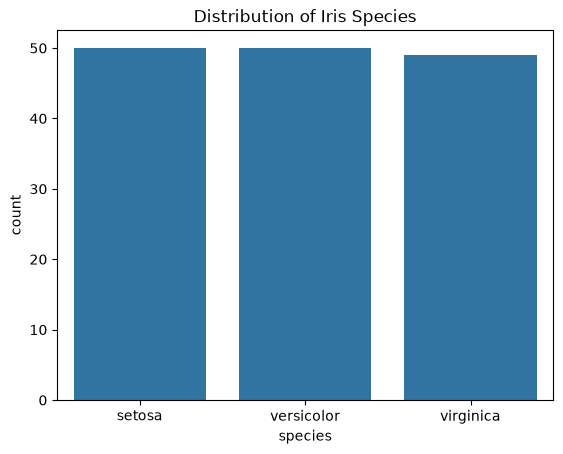

In [14]:
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.show()

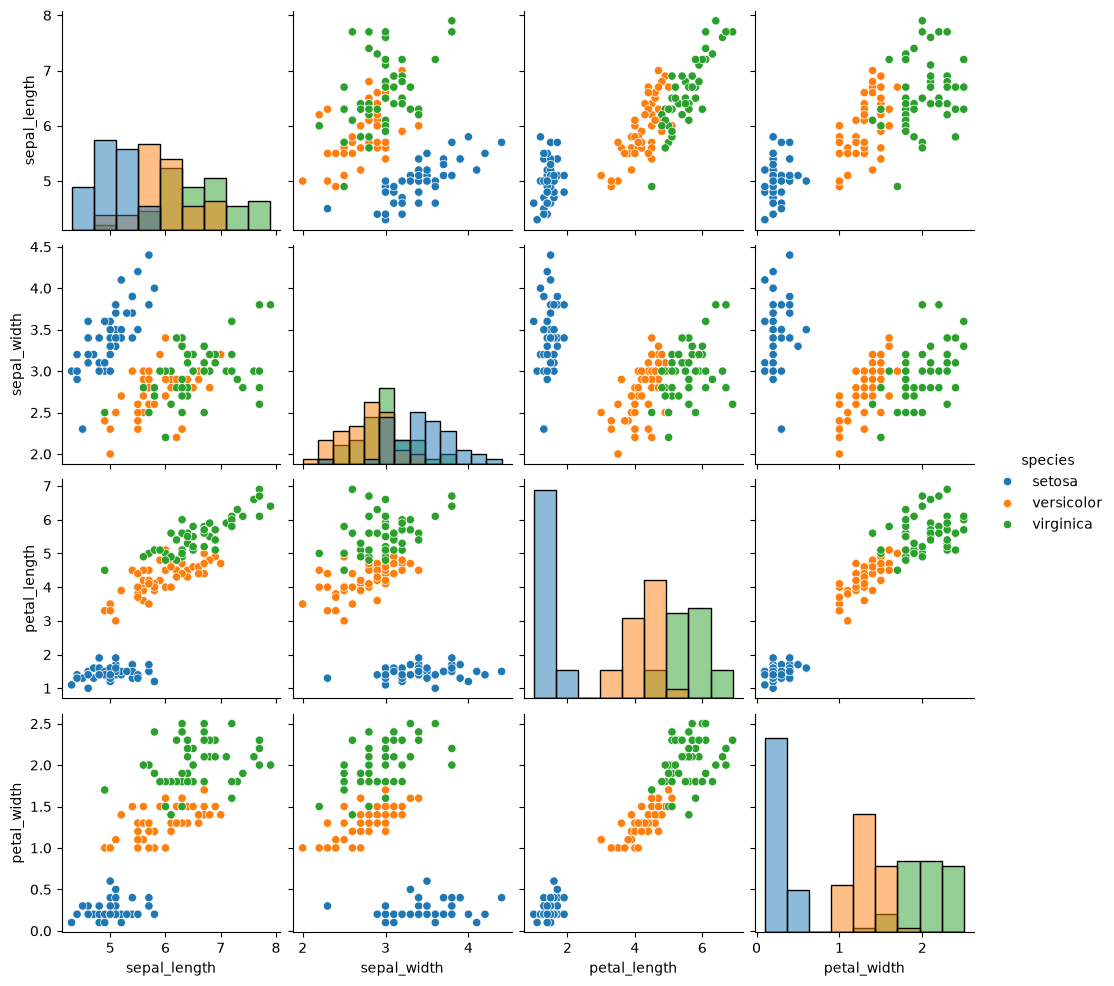

In [15]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)
plt.show()

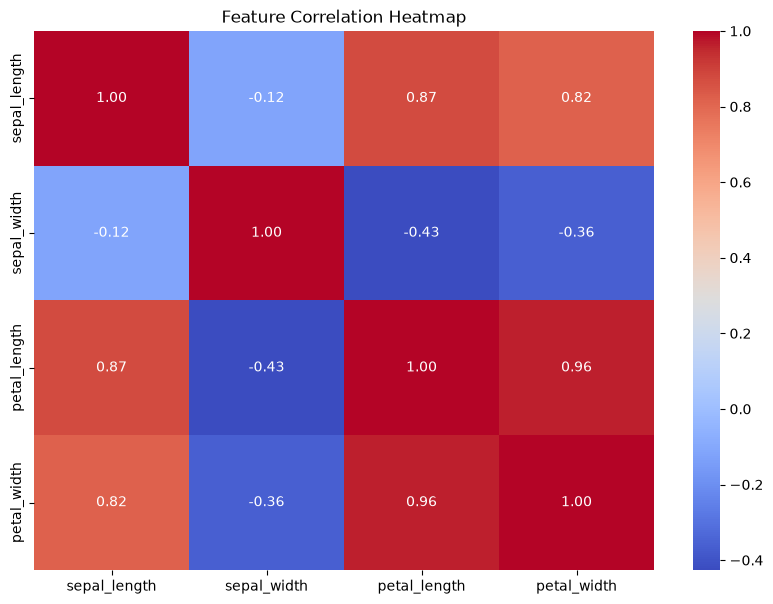

In [16]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

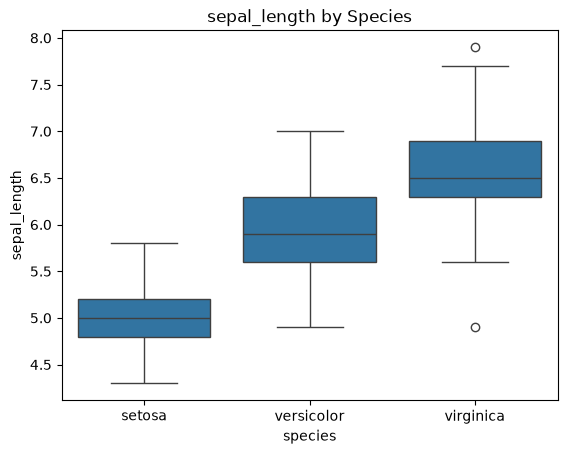

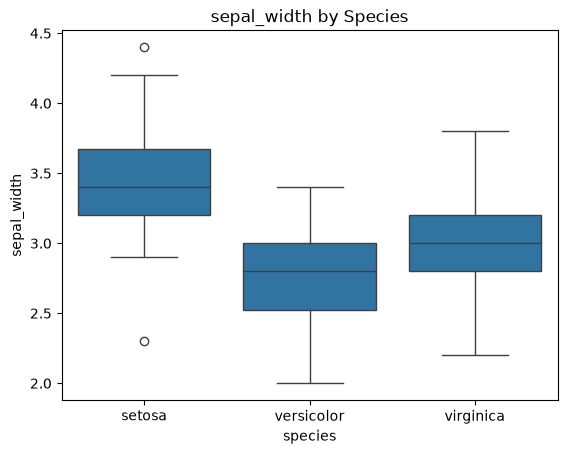

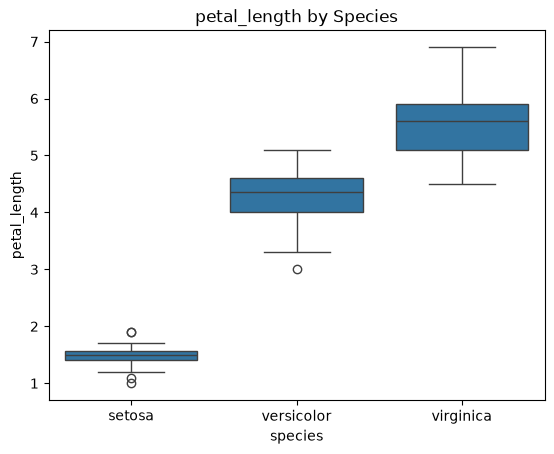

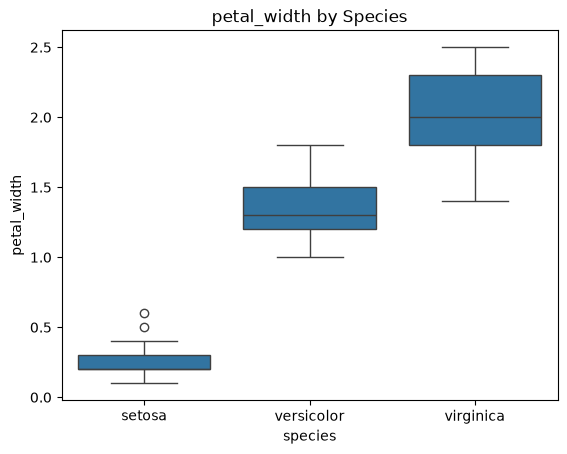

In [17]:
for col in df.select_dtypes(include="number").columns:
    sns.boxplot(data=df, x="species", y=col)
    plt.title(f"{col} by Species")
    plt.show()

In [18]:
X = df.drop("species", axis=1)
y = df['species']

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

logisticregression_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decisiontree_model = DecisionTreeClassifier(
    random_state=42
)

In [22]:
logisticregression_model.fit(X_train_scaled, y_train)

decisiontree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [25]:
logisticregression_pred = logisticregression_model.predict(X_test_scaled)

decisiontree_pred = decisiontree_model.predict(X_test)

### Model Evaluation

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [28]:
def evaluate_model(y_test, y_pred, model_name):

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="weighted"
    )

    recall = recall_score(
        y_test, y_pred, average="weighted"
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted"
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [29]:
logisticregression_results = evaluate_model(
    y_test,
    logisticregression_pred,
    "Logistic Regression"
)

decisiontree_results = evaluate_model(
    y_test,
    decisiontree_pred,
    "Decision Tree"
)

In [30]:
results = pd.DataFrame([
    logisticregression_results,
    decisiontree_results
])

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


### Visualize model comparison

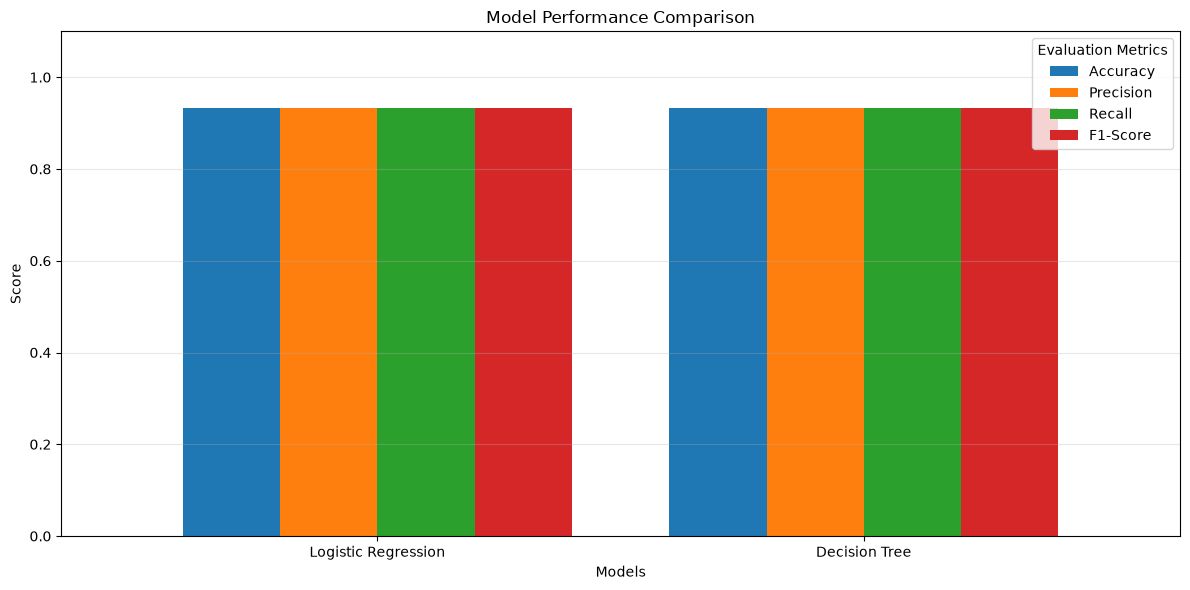

In [31]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_plot = results.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width= 0.8
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Confusion Matrix

#### Logistic Regression confusion matrix:

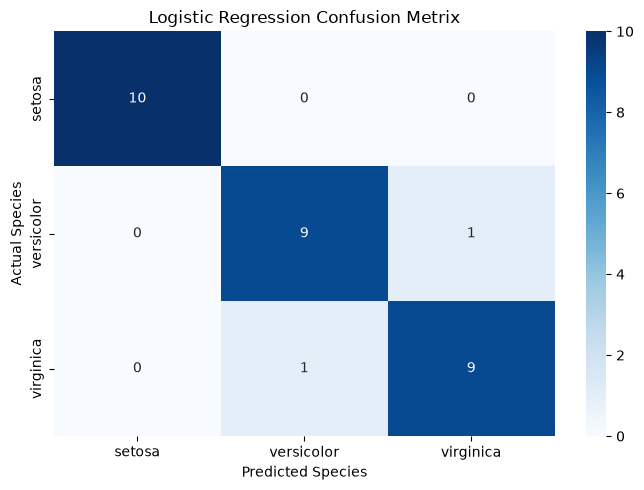

In [32]:
cm_lr = confusion_matrix(y_test, logisticregression_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logisticregression_model.classes_,
    yticklabels= logisticregression_model.classes_
)

plt.title("Logistic Regression Confusion Metrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()
plt.show()